In [1]:
# Import required libraries
import pandas as pd
import json
import matplotlib.dates as mdates

# Analysis window
START, END = "2024-01-01", "2025-01-01"
window = pd.date_range(START, END, freq="h", tz="UTC", inclusive="left", name="Interval Start")

In [2]:
# Import files
caiso = pd.read_csv('data/caiso_raw.csv', index_col='Interval Start', parse_dates=True)
caiso_fill = pd.read_csv("data/caiso_gridstatus_2024-11-01_03.csv", index_col="Interval Start", parse_dates=True)

ercot = pd.read_csv("data/ercot_raw.csv", index_col="Interval Start", parse_dates=True)

## Clean the CAISO and ERCOT data

In [3]:
# Check for missing hours
def missing_hours(df, name, start=START, end=END):
    """Check for duplicate, missing, and NaN hours for an hourly UTC-indexed DataFrame or Series."""
    df = df.to_frame() if isinstance(df, pd.Series) else df
    full = pd.date_range(start, end, freq="h", tz="UTC", inclusive="left")

    dups = df.index[df.index.duplicated()]
    missing = full.difference(df.index)
    nan_rows = df.index[df.isna().any(axis=1)]
    gaps = missing.union(nan_rows).sort_values()

    print(f"---- {name}: {len(df)} rows, expected {len(full)} ----")
    print(f"duplicates: {len(dups)} | missing rows: {len(missing)} | NaN rows: {len(nan_rows)}")
    print("NaNs by column:", df.isna().sum()[lambda s: s > 0].to_dict())

    if len(gaps):
        # Consecutive missing hours share a run ID
        s = gaps.to_series()
        run_id = s.diff().dt.total_seconds().ne(3600).cumsum()
        runs = (s.groupby(run_id.values)
                .agg(start="first", end="last", hours="count"))
        print(runs.to_string(index=False))
    return gaps

# Check raw data for gaps
for name, s in [("CAISO", caiso),
                ("ERCOT", ercot)]:
    missing_hours(s, name)
    print("")

---- CAISO: 8832 rows, expected 8784 ----
duplicates: 0 | missing rows: 0 | NaN rows: 24
NaNs by column: {'Solar': 24, 'Wind': 24}
                    start                       end  hours
2024-11-02 07:00:00+00:00 2024-11-03 06:00:00+00:00     24

---- ERCOT: 8832 rows, expected 8784 ----
duplicates: 0 | missing rows: 0 | NaN rows: 4
NaNs by column: {'Solar': 4}
                    start                       end  hours
2024-07-16 03:00:00+00:00 2024-07-16 03:00:00+00:00      1
2024-11-08 02:00:00+00:00 2024-11-08 02:00:00+00:00      1
2024-11-08 04:00:00+00:00 2024-11-08 05:00:00+00:00      2



In [4]:
# Check overlap between EIA and gridstatus data
overlap = caiso.index.intersection(caiso_fill.index)
diff = (caiso_fill.loc[overlap] - caiso.loc[overlap]) / caiso.loc[overlap]["Load"].mean()
print(diff.abs().mean()) # Mean absolute difference between sources as a fraction of mean load

Load     0.087584
Solar    0.057418
Wind     0.023716
dtype: float64


In [5]:
# Look for lag between gridstatus and EIA data (where discrepancy is minimized)
for lag in [-2, -1, 0, 1, 2]:
    shifted = caiso_fill.shift(lag, freq="h")
    ov = caiso.index.intersection(shifted.index)
    err = ((shifted.loc[ov] - caiso.loc[ov]).abs().mean()
           / caiso.loc[ov, "Load"].mean())
    print(lag, err.round(3).to_dict())

-2 {'Load': 0.113, 'Solar': 0.14, 'Wind': 0.027}
-1 {'Load': 0.101, 'Solar': 0.098, 'Wind': 0.026}
0 {'Load': 0.088, 'Solar': 0.057, 'Wind': 0.024}
1 {'Load': 0.077, 'Solar': 0.027, 'Wind': 0.023}
2 {'Load': 0.086, 'Solar': 0.067, 'Wind': 0.028}


In [6]:
# Shift CAISO data to align with solar peak
caiso.index = caiso.index.shift(-1, freq="h")

In [7]:
# Trim both regions to analysis window
caiso = caiso.reindex(window)
ercot = ercot.reindex(window)

# Check again for missing data
missing_hours(caiso, "CAISO (shifted & trimmed)")
missing_hours(ercot, "ERCOT (trimmed)")

---- CAISO (shifted & trimmed): 8784 rows, expected 8784 ----
duplicates: 0 | missing rows: 0 | NaN rows: 24
NaNs by column: {'Solar': 24, 'Wind': 24}
                    start                       end  hours
2024-11-02 06:00:00+00:00 2024-11-03 05:00:00+00:00     24
---- ERCOT (trimmed): 8784 rows, expected 8784 ----
duplicates: 0 | missing rows: 0 | NaN rows: 4
NaNs by column: {'Solar': 4}
                    start                       end  hours
2024-07-16 03:00:00+00:00 2024-07-16 03:00:00+00:00      1
2024-11-08 02:00:00+00:00 2024-11-08 02:00:00+00:00      1
2024-11-08 04:00:00+00:00 2024-11-08 05:00:00+00:00      2


DatetimeIndex(['2024-07-16 03:00:00+00:00', '2024-11-08 02:00:00+00:00',
               '2024-11-08 04:00:00+00:00', '2024-11-08 05:00:00+00:00'],
              dtype='datetime64[ns, UTC]', freq=None)

In [8]:
# Fill in missing 24 hours of EIA CAISO generation data with gridstatus replacement
gen_cols = ["Solar", "Wind"]
gap = caiso.index[caiso[gen_cols].isna().any(axis=1)]
assert gap.isin(caiso_fill.dropna().index).all(), "Backup data doesn't cover gap"

ov = caiso.index.intersection(caiso_fill.dropna().index).difference(gap)   # Nov 1 and Nov 3
scale = caiso.loc[ov, gen_cols].mean() / caiso_fill.loc[ov, gen_cols].mean()
print(f"Gap: {gap.min()} → {gap.max()} ({len(gap)} h); EIA/CAISO scale:", scale.round(3).to_dict())

caiso.loc[gap, gen_cols] = caiso_fill.loc[gap, gen_cols] * scale

Gap: 2024-11-02 06:00:00+00:00 → 2024-11-03 05:00:00+00:00 (24 h); EIA/CAISO scale: {'Solar': 0.876, 'Wind': 0.998}


In [9]:
# Fill in missing ERCOT generation hours with zero (all missing data at night)
night_gaps = ercot.index[ercot["Solar"].isna()]
print(night_gaps.tz_convert("US/Central")) # Confirm data is at night (no solar energy)
assert night_gaps.tz_convert("US/Central").hour.isin(range(19, 24)).all(), "Daytime solar gap found"
ercot.loc[night_gaps, "Solar"] = 0

DatetimeIndex(['2024-07-15 22:00:00-05:00', '2024-11-07 20:00:00-06:00',
               '2024-11-07 22:00:00-06:00', '2024-11-07 23:00:00-06:00'],
              dtype='datetime64[ns, US/Central]', name='Interval Start', freq=None)


In [10]:
# Clip minimum of all values to zero
caiso[["Solar", "Load", "Wind"]] = caiso[["Solar", "Load", "Wind"]].clip(lower=0)
ercot[["Solar", "Load", "Wind"]] = ercot[["Solar", "Load", "Wind"]].clip(lower=0)

In [11]:
# Rename columns
cols = {"Load": "demand", "Solar": "solar", "Wind": "wind"}
caiso = caiso.rename(columns=cols)
ercot = ercot.rename(columns=cols)

In [12]:
# Add local hour
caiso["local_hour"] = caiso.index.tz_convert("America/Los_Angeles").hour
ercot["local_hour"] = ercot.index.tz_convert("America/Chicago").hour

In [13]:
# Check again for missing values
missing_hours(caiso, "CAISO cleaned")
missing_hours(ercot, "ERCOT cleaned")

caiso.to_csv("data/caiso_clean.csv")
ercot.to_csv("data/ercot_clean.csv")

---- CAISO cleaned: 8784 rows, expected 8784 ----
duplicates: 0 | missing rows: 0 | NaN rows: 0
NaNs by column: {}
---- ERCOT cleaned: 8784 rows, expected 8784 ----
duplicates: 0 | missing rows: 0 | NaN rows: 0
NaNs by column: {}


## Examine renewable shares in each region

In [14]:
print("Average share of CAISO demand met by solar:", round(caiso["solar"].mean()/caiso["demand"].mean()*100,2),"%")
print("Average share of CAISO demand met by wind:", round(caiso["wind"].mean()/caiso["demand"].mean()*100,2),"%")
print("Average total share of CAISO demand met by wind + solar:", round((caiso["solar"].mean() + caiso["wind"].mean())/caiso["demand"].mean()*100,2), "%")
print("Average CAISO ratio of solar to wind:", round(caiso["solar"].mean()/caiso["wind"].mean(),2))
print("")
print("Average share of ERCOT demand met by solar:", round(ercot["solar"].mean()/ercot["demand"].mean()*100,2),"%")
print("Average share of ERCOT demand met by wind:", round(ercot["wind"].mean()/ercot["demand"].mean()*100,2),"%")
print("Average total share of ERCOT demand met by wind + solar:", round((ercot["solar"].mean() + ercot["wind"].mean())/ercot["demand"].mean()*100,2), "%")
print("Average ERCOT ratio of wind to solar:", round(ercot["wind"].mean()/ercot["solar"].mean(),2))

Average share of CAISO demand met by solar: 20.06 %
Average share of CAISO demand met by wind: 8.98 %
Average total share of CAISO demand met by wind + solar: 29.04 %
Average CAISO ratio of solar to wind: 2.23

Average share of ERCOT demand met by solar: 10.3 %
Average share of ERCOT demand met by wind: 24.1 %
Average total share of ERCOT demand met by wind + solar: 34.39 %
Average ERCOT ratio of wind to solar: 2.34


## Prepare the regions for model training

Reshape generation and demand data such that the ratio of solar-to-wind generation is the main differentiator between the two regions.
* Normalize demand to account for differences in region size
* Set the total renewable share (wind + solar) equal to a constant share of total demand over the training year
* Rather than explicitly modeling gas, nuclear, hydropower, and imports, set firm capacity equal to a cap (95th percentile of training residual demand: demand - renewables), so 5% of training hours are short without a battery
* The battery can only charge from a renewable surplus, so enough surplus hours must exist after rescaling
* RL battery dispatch agent must learn to cover the remaining load not met in real-time by renewables and firm capacity

Split the data into training and test sets. Split each month into training and test days to prevent seasonal differences in renewable generation and demand from affecting model training.

In [15]:
# Set constants for simulated environments
RENEWABLE_SHARE = 0.80 # Total share of demand met by renewables across the year (same across regions)
FIRM_QUANTILE = 0.95 # This quantile of training residual demand
TEST_START_DAY = 22 # Each month, 21 days are training days, remaining are test (to remove seasonal artifacts)

In [16]:
# Load data and split into training and test sets
def load_clean(name,  tz):
    df = pd.read_csv(f"data/{name}_clean.csv", index_col="Interval Start", parse_dates=True)
    df["local_hour"] = df.index.tz_convert(tz).hour
    df["is_test"] = df.index.day >= TEST_START_DAY
    return df

In [17]:
# Normalize training data (same factor will be applied to unseen test data)
def fit_normalizer(train):
    scale = train["demand"].mean() # Mean demand in region
    d, s, w = (train[c] / scale for c in ["demand", "solar", "wind"]) # Convert demand, wind, and solar to these units
    k = RENEWABLE_SHARE * d.sum() / (s + w).sum() # Calculate renewable multiplier
    firm = (d - k * (s + w)).quantile(FIRM_QUANTILE) # Calculate the backup capacity
    return {"scale_MW": float(scale), "k": float(k), "firm": float(firm)}

def apply_normalizer(df, p):
    out = pd.DataFrame(index=df.index)
    out["demand"] = df["demand"] / p["scale_MW"]
    out["solar"] = df["solar"] / p["scale_MW"] * p["k"]
    out["wind"] = df["wind"] / p["scale_MW"] * p["k"]

    ren = out["solar"] + out["wind"] # Total share of renewables
    out["ren_surplus"] = (ren - out["demand"]).clip(lower=0) # Surplus renewable energy available for charging
    out["residual"] = (out["demand"] - ren).clip(lower=0) # Demand left after renewables
    
    out["firm_gen_nobatt"] = out["residual"].clip(upper=p["firm"]) # Firm output without battery
    out["unserved_nobatt"] = (out["residual"] - p["firm"]) # Shortfall without battery
    out["firm_cap"] = p["firm"]

    out["local_hour"] = df["local_hour"]
    out["is_test"] = df["is_test"]
    return out

In [18]:
# Prepare CAISO and ERCOT data and determine normalized expected unserved energy in each region
params = {}
for name, tz in [("caiso", "America/Los_Angeles"), ("ercot", "America/Chicago")]:
    df = load_clean(name, tz)
    p = fit_normalizer(df.loc[~df["is_test"]]) # Calculate normalizer
    norm = apply_normalizer(df, p) # Apply normalizer

    # Determine no-battery baseline and unserved energy as a % of demand
    deficit = (norm["unserved_nobatt"]).clip(lower=0)
    for split, mask in [("train", ~norm["is_test"]), ("test", norm["is_test"])]:
        neue = 100 * deficit[mask].sum() / norm.loc[mask, "demand"].sum()
        deficit_hours = (deficit[mask] > 0).sum()
        print(f"{name} {split}: NEUE {neue:.2f}%, deficit hours {deficit_hours}")

    params[name] = p
    norm.to_csv(f"data/{name}_norm.csv")

params["settings"] = {"renewable_share": RENEWABLE_SHARE, "firm_quantile": FIRM_QUANTILE,
                      "test_start_day": TEST_START_DAY}
json.dump(params, open("data/normalization_params.json", "w"), indent=2)
print(json.dumps(params, indent=2))

caiso train: NEUE 0.59%, deficit hours 303
caiso test: NEUE 0.40%, deficit hours 90
ercot train: NEUE 0.55%, deficit hours 303
ercot test: NEUE 0.54%, deficit hours 173
{
  "caiso": {
    "scale_MW": 25710.1271494709,
    "k": 2.7837259833644743,
    "firm": 0.9653141951063545
  },
  "ercot": {
    "scale_MW": 52863.81398809524,
    "k": 2.3166990711566298,
    "firm": 0.7451728319066019
  },
  "settings": {
    "renewable_share": 0.8,
    "firm_quantile": 0.95,
    "test_start_day": 22
  }
}


In [19]:
import pandas as pd
import matplotlib.pyplot as plt

TZ = {"caiso": "America/Los_Angeles", "ercot": "America/Chicago"}
COLORS = {"demand": "#2a78d6", "solar": "#eb6834", "wind": "#1baf7a"}

# Load normalized data and compute supply and deficit
data = {}
for name, tz in TZ.items():
    df = pd.read_csv(f"data/{name}_norm.csv", index_col="Interval Start", parse_dates=True)
    df.index = df.index.tz_convert(tz)                           # local time for plotting
    df["supply"] = df["solar"] + df["wind"] + df["firm_cap"]
    df["deficit"] = (df["demand"] - df["supply"]).clip(lower=0)  # unmet demand, no battery
    data[name] = df

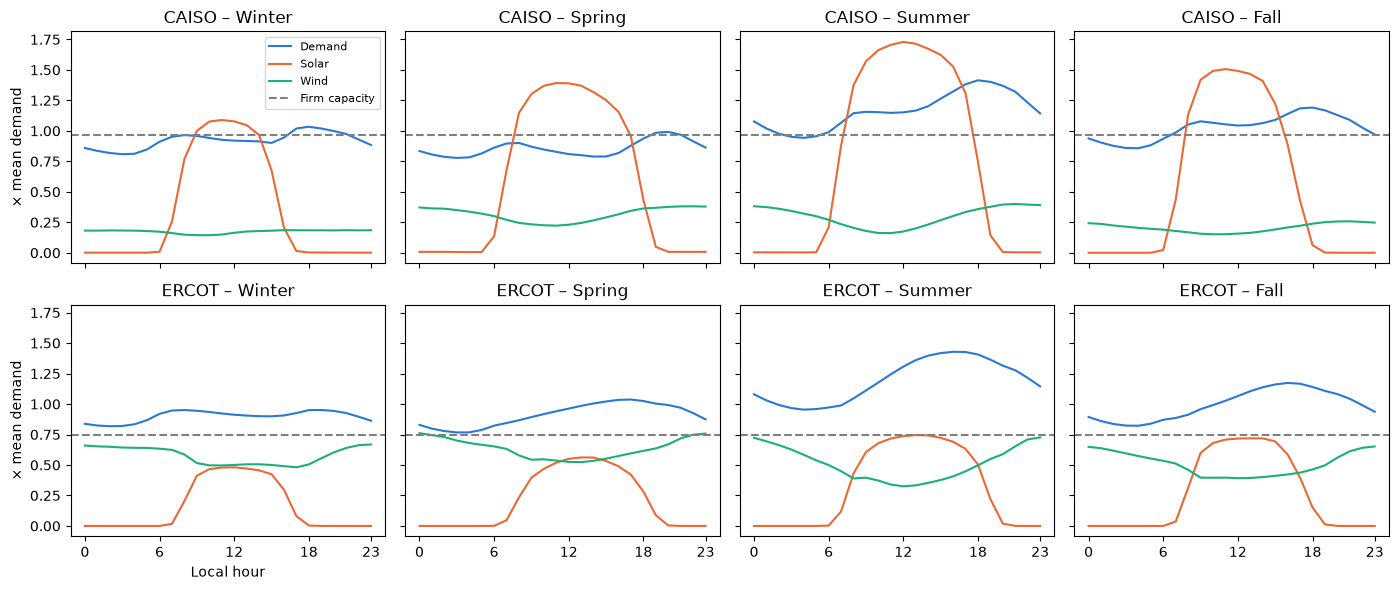

In [20]:
seasons = {"Winter": [12, 1, 2], "Spring": [3, 4, 5], "Summer": [6, 7, 8], "Fall": [9, 10, 11]}

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
for r, name in enumerate(data):
    df = data[name]
    for c, (season, months) in enumerate(seasons.items()):
        ax = axes[r, c]
        avg = df[df.index.month.isin(months)].groupby("local_hour").mean(numeric_only=True)

        for col, color in COLORS.items():
            ax.plot(avg.index, avg[col], color=color, label=col.capitalize())
        ax.axhline(df["firm_cap"].iloc[0], color="gray", ls="--", label="Firm capacity")

        ax.set_title(f"{name.upper()} – {season}")
        ax.set_xticks([0, 6, 12, 18, 23])
axes[1, 0].set_xlabel("Local hour")
axes[0, 0].set_ylabel("× mean demand")
axes[1, 0].set_ylabel("× mean demand")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

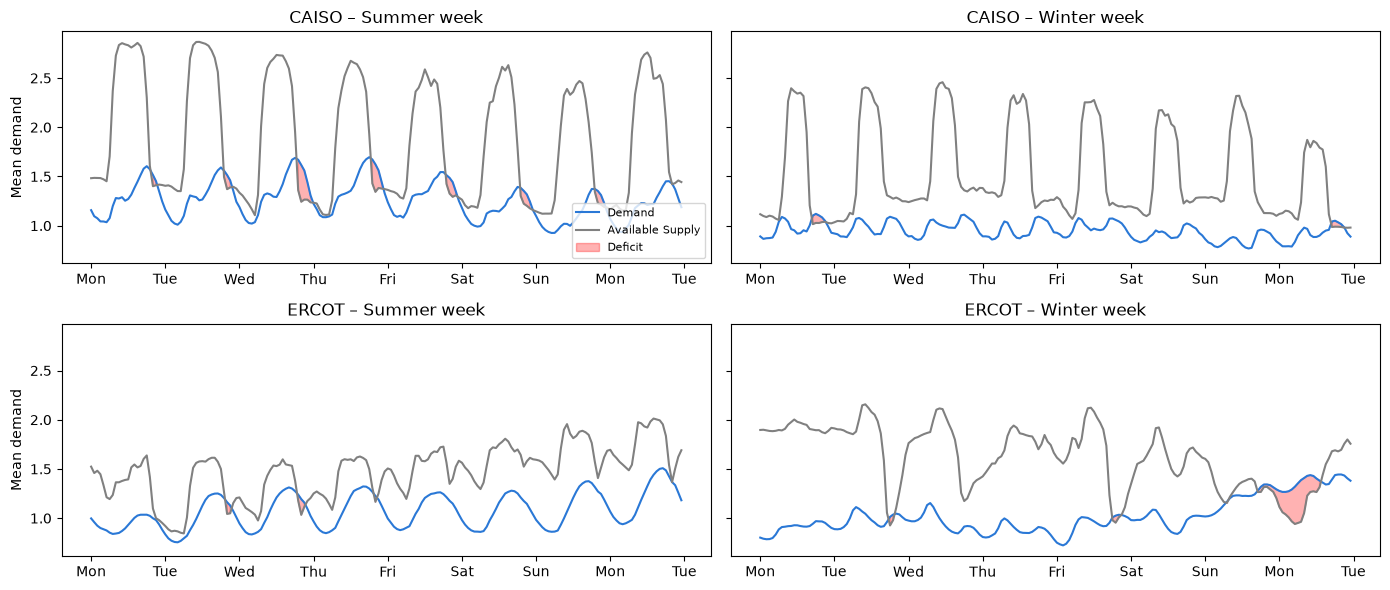

In [21]:
weeks = {"Summer": ("2024-07-08", "2024-07-15"), "Winter": ("2024-01-08", "2024-01-15")}

fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharey=True)
for r, name in enumerate(data):
    for c, (label, (start, end)) in enumerate(weeks.items()):
        ax = axes[r, c]
        wk = data[name].loc[start:end]

        ax.plot(wk.index, wk["demand"], color=COLORS["demand"], label="Demand")
        ax.plot(wk.index, wk["supply"], color="gray", label="Available Supply")
        ax.fill_between(wk.index, wk["supply"], wk["demand"],
                        where=wk["deficit"] > 0, color="red", alpha=0.3, label="Deficit")

        ax.set_title(f"{name.upper()} – {label} week")
        ax.xaxis.set_major_locator(mdates.DayLocator(tz=wk.index.tz))           # one tick per day
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%a", tz=wk.index.tz))  # Mon, Tue, ...
axes[0, 0].set_ylabel("Mean demand")
axes[1, 0].set_ylabel("Mean demand")
axes[0, 0].legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()